# 0a_02 Counting: How Many Ways Can It Happen?

**Learning objectives**
- Use the **multiplication rule** to count outcomes of several steps.
- Tell **permutations** (order matters) from **combinations** (order does not), with and without repetition, and compute them with factorials and $\binom nk$.
- Turn a count into a probability: $P=\dfrac{\text{favourable}}{\text{total}}$.
- Solve classic problems: the **lottery**, the **birthday problem** and **poker hands**, and check each by simulation.

**Prerequisites:** [0a_01 Outcomes, events and the sample space](0a_01_sets_events_sample_space.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools
from scipy import special

## 2. Prerequisite recap

- When all outcomes of an experiment are **equally likely**, $P(A)=|A|/|S|$ (0a_01). The hard part is then **counting** $|A|$ and $|S|$ without listing them.
- A **factorial** is a product of consecutive integers: $n!=n\cdot(n-1)\cdots2\cdot1$, with $0!=1$. So $5!=120$.
- A **power** $n^k$ means $n$ multiplied by itself $k$ times: $2^3=8$.

## 3. Intuition and story

How many different 4-digit PINs are there? How many ways can 10 runners finish 1st, 2nd and 3rd? How many different 6-number lottery tickets? Listing them is hopeless, but **structure** makes them easy to count.

The only tool behind everything in this lesson is the **multiplication rule**: if a task has several steps and step 1 can be done in $m_1$ ways, step 2 in $m_2$ ways, and so on, then the whole task can be done in $m_1\times m_2\times\cdots$ ways. Permutations and combinations are just the multiplication rule applied to "choose some items from a group", with one extra question: **does the order of the chosen items matter?**

## 4. Formal definitions

| Situation | Name | Formula | Example |
|---|---|---|---|
| $k$ independent steps with $m_1,\dots,m_k$ choices | multiplication rule | $m_1m_2\cdots m_k$ | outfit: 4 shirts $\times$ 3 trousers $=12$ |
| Choose $k$ from $n$, order matters, **repetition allowed** | words / sequences | $n^k$ | 4-digit PINs: $10^4=10{,}000$ |
| Choose $k$ from $n$, order matters, **no repetition** | **permutations** | $P(n,k)=\dfrac{n!}{(n-k)!}$ | podium of 3 from 10: $10\cdot9\cdot8=720$ |
| Arrange all $n$ distinct items | permutations of $n$ | $n!$ | 5 books on a shelf: $120$ |
| Choose $k$ from $n$, order **does not** matter, no repetition | **combinations** | $\binom nk=\dfrac{n!}{k!\,(n-k)!}$ | a committee of 3 from 10: $120$ |
| Arrange $n$ items with repeats ($n_1$ of one kind, $n_2$ of another, ...) | multinomial | $\dfrac{n!}{n_1!\,n_2!\cdots}$ | letters of BANANA: $\dfrac{6!}{3!\,2!\,1!}=60$ |

**Probability from counting.** If all outcomes are equally likely, $P(A)=\dfrac{\#\text{ways for }A}{\#\text{ways in total}}$.

**Properties of $\binom nk$:** $\binom nk=\binom n{n-k}$, $\binom n0=\binom nn=1$, $\binom nk=\binom{n-1}{k-1}+\binom{n-1}k$ (Pascal's rule), and $\sum_k\binom nk=2^n$.

## 5. Derivations

### 5.1 Permutations without repetition
For the first place we have $n$ choices, for the second $n-1$ (one item is used), ..., for the $k$-th place $n-k+1$. By the multiplication rule $P(n,k)=n(n-1)\cdots(n-k+1)=\dfrac{n!}{(n-k)!}$. **In plain words.** Every time we pick an item, one fewer remains, so the number of choices shrinks by one.

### 5.2 Combinations from permutations
Each unordered group of $k$ items can be arranged in $k!$ orders. So $P(n,k)$ counts every group $k!$ times, and the number of groups is $$\binom nk=\frac{P(n,k)}{k!}=\frac{n!}{k!\,(n-k)!}.$$ **In plain words.** Count the ordered picks, then divide by the number of ways to shuffle each pick, because shuffling does not change the group.

### 5.3 Pascal's rule
Fix one special item. A group of $k$ items either contains it (choose the other $k-1$ from $n-1$: $\binom{n-1}{k-1}$) or not (choose all $k$ from $n-1$: $\binom{n-1}k$). Adding the two cases gives $\binom nk$. **In plain words.** Each row of Pascal's triangle is built by adding the two numbers above it.

### 5.4 Why $\sum_k\binom nk=2^n$
Each of $n$ items is either in a subset or out: $2$ choices each, $2^n$ subsets in total; grouping the subsets by size $k$ gives $\sum\binom nk$.

### 5.5 The birthday problem
$P(\text{all }n\text{ birthdays differ})=\dfrac{365}{365}\cdot\dfrac{364}{365}\cdots\dfrac{365-n+1}{365}=\dfrac{365!}{(365-n)!\,365^n}$, and $P(\text{at least one shared})=1-$ that (complement rule of 0a_01). **In plain words.** Add people one at a time: the $j$-th person must avoid the $j-1$ birthdays already taken.

## 6. Properties and relationships

- **Order matters or not?** If swapping two chosen items gives a different result (a podium, a PIN) use permutations; if not (a committee, a lottery ticket) use combinations. Combinations $=$ permutations $/\,k!$.
- **Repetition allowed or not?** PINs allow repeated digits ($n^k$); a podium does not.
- **Symmetry:** choosing which $k$ items to take is the same as choosing which $n-k$ to leave: $\binom nk=\binom n{n-k}$.
- **Growth:** factorials explode ($20!\approx2.4\times10^{18}$), which is why we compute with `math.comb` or logarithms for large $n$.
- **Link to later lessons:** $\binom nk$ is the heart of the **Binomial** distribution (Module 01), and counting favourable draws of a group without replacement gives the **Hypergeometric** distribution (Module 01), used here for the lottery.

## 7. 2D visuals

### 7.1 Pascal's triangle
Each number is a $\binom nk$ (the number of groups of $k$ from $n$). Rows add to $2^n$; the middle is the largest.

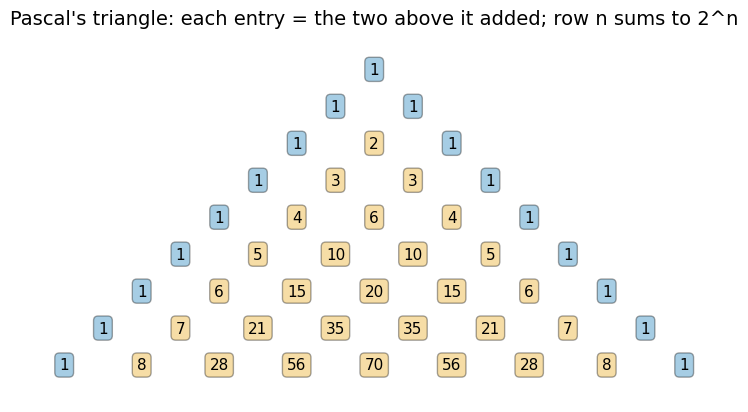

In [2]:
rows = 9
fig, ax = plt.subplots(figsize=(9, 4.8))
for n_ in range(rows):
    for k_ in range(n_ + 1):
        ax.text(k_ - n_ / 2, -n_, str(math.comb(n_, k_)), ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="round", facecolor=MAIN if k_ in (0, n_) else SIM, alpha=0.35))
ax.set_xlim(-rows / 2, rows / 2); ax.set_ylim(-rows, 1); ax.axis("off"); ax.set_title("Pascal's triangle: each entry = the two above it added; row n sums to 2^n")
plt.show()
assert all(sum(math.comb(n_, k_) for k_ in range(n_ + 1)) == 2**n_ for n_ in range(rows))

### 7.2 The multiplication rule as a tree
A 3-letter code from {A, B} with repetition: $2\times2\times2=8$ leaves. Each extra step multiplies the number of paths.

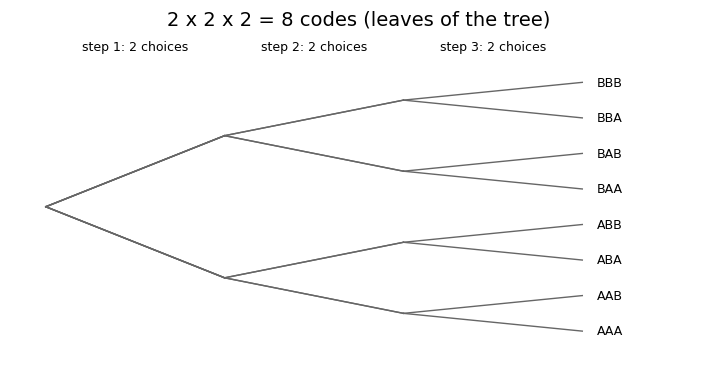

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
paths = list(itertools.product("AB", repeat=3))
for i, path in enumerate(paths):
    y_leaf = i
    x_prev, y_prev = 0, 3.5
    for depth in range(1, 4):
        group = 2 ** (3 - depth)
        y_now = (i // group) * group + (group - 1) / 2
        ax.plot([x_prev, depth], [y_prev, y_now], color=NEUTRAL, linewidth=1)
        x_prev, y_prev = depth, y_now
    ax.text(3.08, y_leaf, "".join(path), va="center", fontsize=9)
for depth in range(0, 3):
    ax.text(depth + 0.5, 7.9, f"step {depth + 1}: 2 choices", ha="center", fontsize=9)
ax.set_xlim(-0.2, 3.7); ax.set_ylim(-0.7, 8.4); ax.axis("off"); ax.set_title("2 x 2 x 2 = 8 codes (leaves of the tree)")
plt.show()

### 7.3 Permutations versus combinations
How many ways to pick $k$ of 10 people: ordered (permutations) against unordered (combinations). The gap is exactly $k!$.

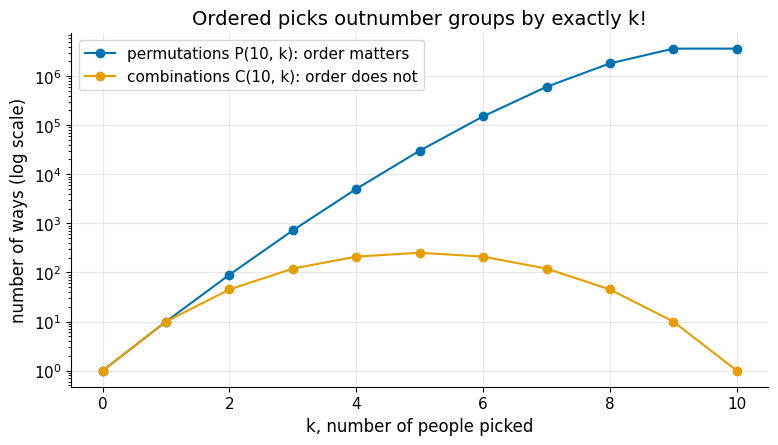

In [4]:
ks = np.arange(0, 11)
perm = [math.perm(10, k_) for k_ in ks]; comb = [math.comb(10, k_) for k_ in ks]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.semilogy(ks, perm, "o-", color=MAIN, label="permutations P(10, k): order matters")
ax.semilogy(ks, comb, "o-", color=SIM, label="combinations C(10, k): order does not")
ax.set_xlabel("k, number of people picked"); ax.set_ylabel("number of ways (log scale)"); ax.set_title("Ordered picks outnumber groups by exactly k!"); ax.legend()
plt.show()
assert all(perm[k_] == comb[k_] * math.factorial(k_) for k_ in range(11))

### 7.4 The birthday problem
The chance that at least two of $n$ people share a birthday rises surprisingly fast: **23 people** are enough for better than 50 %.

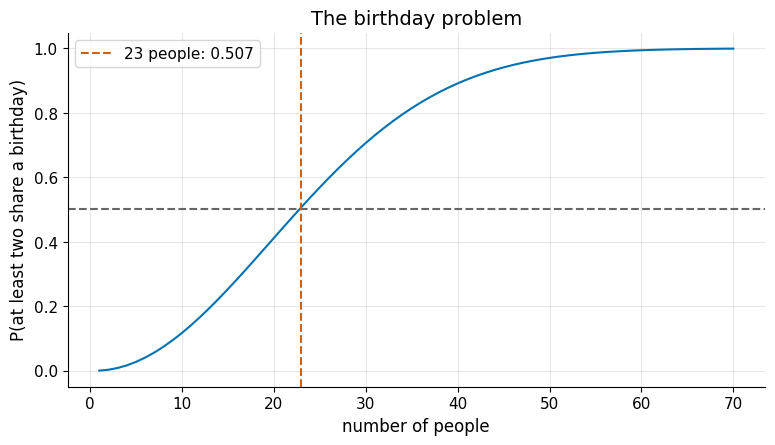

{10: np.float64(0.1169), 23: np.float64(0.5073), 30: np.float64(0.7063), 50: np.float64(0.9704), 70: np.float64(0.9992)}


In [5]:
def p_shared(n_people, days=365):
    return 1 - np.prod((days - np.arange(n_people)) / days)
ns = np.arange(1, 71)
probs = np.array([p_shared(n_) for n_ in ns])
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(ns, probs, color=MAIN)
ax.axhline(0.5, color=NEUTRAL, linestyle="--"); ax.axvline(23, color=HIGHLIGHT, linestyle="--", label=f"23 people: {p_shared(23):.3f}")
ax.set_xlabel("number of people"); ax.set_ylabel("P(at least two share a birthday)"); ax.set_title("The birthday problem"); ax.legend()
plt.show()
print({n_: round(p_shared(n_), 4) for n_ in (10, 23, 30, 50, 70)})
assert p_shared(22) < 0.5 < p_shared(23)

## 8. 3D visuals

### 8.1 Static: $\log_{10}\binom nk$ over $(n,k)$
A ridge along $k=n/2$: the number of groups is largest when we pick half the items. The surface also shows how huge the counts get (a lottery ticket $\binom{49}{6}$ is already near $10^{7}$).

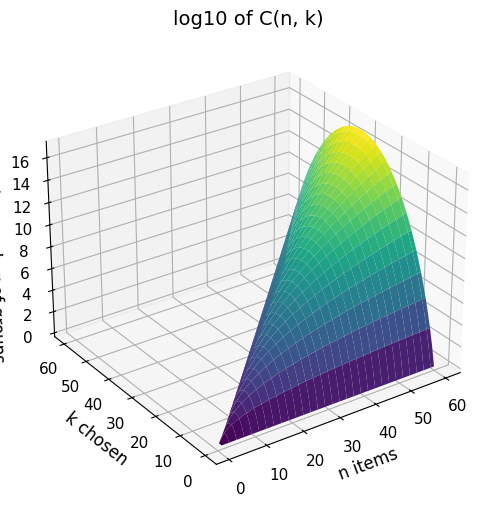

In [6]:
n_ax = np.arange(1, 61); k_ax = np.arange(0, 61)
Z = np.array([[math.log10(math.comb(n_, k_)) if k_ <= n_ else np.nan for n_ in n_ax] for k_ in k_ax])
Ng, Kg = np.meshgrid(n_ax, k_ax)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng, Kg, np.ma.masked_invalid(Z), cmap="viridis", edgecolor="none")
ax.set_title("log10 of C(n, k)"); ax.set_xlabel("n items"); ax.set_ylabel("k chosen"); ax.set_zlabel("log10 of the number of groups"); ax.view_init(elev=28, azim=-125)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read $\log_{10}\binom nk$ for any $(n,k)$.

In [7]:
fig = go.Figure(go.Surface(x=n_ax, y=k_ax, z=Z, colorscale="Viridis"))
fig.update_layout(title="log10 C(n, k)", width=750, height=550, scene=dict(xaxis_title="n", yaxis_title="k", zaxis_title="log10 C(n, k)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Random shuffles: every ordering is equally likely
Shuffle 4 items 120,000 times; each of the $4!=24$ orderings should appear about $120000/24=5000$ times. This is why permutation counts give exact probabilities for shuffles.

In [8]:
items = np.array(list("ABCD"))
counts = pd.Series(["".join(rng.permutation(items)) for _ in range(120_000)]).value_counts()
print(f"{len(counts)} different orderings, counts from {counts.min()} to {counts.max()} (expected {120_000 // 24})")
assert len(counts) == math.factorial(4) and counts.min() > 4600 and counts.max() < 5400

24 different orderings, counts from 4822 to 5173 (expected 5000)


### 9.2 Birthdays by simulation
Generate random birthdays for groups of 23 and check how often at least two coincide.

In [9]:
trials = 50_000
birthdays = rng.integers(0, 365, size=(trials, 23))
shared = np.array([len(set(row)) < 23 for row in birthdays])
print(f"simulated P(shared birthday among 23) = {shared.mean():.4f} | exact {p_shared(23):.4f}")
assert abs(shared.mean() - p_shared(23)) < 0.01

simulated P(shared birthday among 23) = 0.5081 | exact 0.5073


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
print("factorial:", math.factorial(5), "| permutations math.perm(10, 3):", math.perm(10, 3), "| combinations math.comb(49, 6):", math.comb(49, 6))
print("scipy.special.comb(49, 6, exact=True):", special.comb(49, 6, exact=True), "| log of a huge count: special.gammaln(101) - ... or use math.lgamma(101) =", round(math.lgamma(101), 2))
print("list the groups: list(itertools.combinations('ABCD', 2)) ->", list(itertools.combinations("ABCD", 2)))
print("list the orderings: list(itertools.permutations('ABC', 2)) ->", list(itertools.permutations("ABC", 2)))
print("product with repetition: len(list(itertools.product('01', repeat=4))) ->", len(list(itertools.product("01", repeat=4))), "= 2^4")
print("random subset without replacement: rng.choice(49, size=6, replace=False) + 1 ->", np.sort(rng.choice(49, size=6, replace=False)) + 1)
lottery = stats.hypergeom(M=49, n=6, N=6)
print("scipy.stats.hypergeom: P(matching exactly 3 of 6) =", round(lottery.pmf(3), 6), "= C(6,3) C(43,3) / C(49,6)")

factorial: 120 | permutations math.perm(10, 3): 720 | combinations math.comb(49, 6): 13983816
scipy.special.comb(49, 6, exact=True): 13983816 | log of a huge count: special.gammaln(101) - ... or use math.lgamma(101) = 363.74
list the groups: list(itertools.combinations('ABCD', 2)) -> [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
list the orderings: list(itertools.permutations('ABC', 2)) -> [('A', 'B'), ('A', 'C'), ('B', 'A'), ('B', 'C'), ('C', 'A'), ('C', 'B')]
product with repetition: len(list(itertools.product('01', repeat=4))) -> 16 = 2^4
random subset without replacement: rng.choice(49, size=6, replace=False) + 1 -> [ 1 17 22 33 38 42]
scipy.stats.hypergeom: P(matching exactly 3 of 6) = 0.01765 = C(6,3) C(43,3) / C(49,6)


## 11. Real-world worked examples

---
### Example 1 (main): the 6-out-of-49 lottery

**Scenario.** A lottery draws **6 numbers from 1 to 49** (order irrelevant). You buy one ticket with 6 numbers. Prizes: 6 matches jackpot, 5, 4 and 3 matches smaller prizes.

**Questions**
1. How many different tickets are possible?
2. What is the probability of the **jackpot** (all 6 match)?
3. What is the probability of matching **exactly 3** numbers?
4. What is the probability of winning **any prize** (at least 3 matches)?
5. If you play every week for 1,000 years (52,000 tickets), what is the chance of hitting the jackpot at least once?

### 11.1 By hand
**Q1.** Order does not matter, no repeats: $\binom{49}{6}=\dfrac{49\cdot48\cdot47\cdot46\cdot45\cdot44}{6!}=\dfrac{10{,}068{,}347{,}520}{720}=13{,}983{,}816$.

**Q2.** Exactly one ticket wins: $P=\dfrac1{13{,}983{,}816}=7.15\times10^{-8}$.

**Q3.** Choose which 3 of the 6 winning numbers you hold: $\binom63=20$; the other 3 of your numbers must come from the 43 non-winning numbers: $\binom{43}3=12{,}341$. So $P(\text{exactly 3})=\dfrac{20\times12{,}341}{13{,}983{,}816}=\dfrac{246{,}820}{13{,}983{,}816}=0.01765$ (about 1 in 57).

**Q4.** Exactly 4: $\binom64\binom{43}2=15\times903=13{,}545$; exactly 5: $\binom65\binom{43}1=6\times43=258$; exactly 6: $1$. Total favourable $=246{,}820+13{,}545+258+1=260{,}624$, so $P(\ge3)=\dfrac{260{,}624}{13{,}983{,}816}=0.01864$ (about 1 in 54).

**Q5.** The chance of at least one jackpot is $1-(1-7.15\times10^{-8})^{52{,}000}\approx52{,}000\times7.15\times10^{-8}=0.0037$ (complement rule).

In [11]:
total = math.comb(49, 6)
exact = {m: math.comb(6, m) * math.comb(43, 6 - m) for m in range(7)}
print(f"Q1: {total:,} tickets")
print(f"Q2: P(jackpot) = 1/{total:,} = {1 / total:.3e}")
print(f"Q3: exactly 3 matches: {exact[3]:,} tickets -> P = {exact[3] / total:.5f} (about 1 in {total / exact[3]:.0f})")
at_least3 = sum(exact[m] for m in range(3, 7))
print(f"Q4: at least 3 matches: {at_least3:,} tickets -> P = {at_least3 / total:.5f} (about 1 in {total / at_least3:.0f})")
print(f"Q5: P(at least one jackpot in 52,000 tickets) = {1 - (1 - 1 / total) ** 52_000:.5f}")
print("all match counts:", {m: round(exact[m] / total, 6) for m in range(7)}, "| they add to", round(sum(exact.values()) / total, 10))

Q1: 13,983,816 tickets
Q2: P(jackpot) = 1/13,983,816 = 7.151e-08
Q3: exactly 3 matches: 246,820 tickets -> P = 0.01765 (about 1 in 57)
Q4: at least 3 matches: 260,624 tickets -> P = 0.01864 (about 1 in 54)
Q5: P(at least one jackpot in 52,000 tickets) = 0.00371
all match counts: {0: 0.435965, 1: 0.413019, 2: 0.132378, 3: 0.01765, 4: 0.000969, 5: 1.8e-05, 6: 0.0} | they add to 1.0


### 11.2 In code with `scipy`, and the asserts

In [12]:
lot = stats.hypergeom(M=49, n=6, N=6)                       # scipy's hypergeometric: population 49, 6 'good' numbers, 6 drawn
assert total == 13_983_816 and exact[3] == 246_820 and at_least3 == 260_624
assert all(np.isclose(lot.pmf(m), exact[m] / total) for m in range(7))                    # same numbers from scipy
assert np.isclose(sum(exact.values()), total) and np.isclose(lot.sf(2), at_least3 / total)  # all matches add up; sf(2) = P(X >= 3)
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Draw the winning numbers and a ticket at random 300,000 times. The jackpot is too rare to see, but the 3-or-more frequency can be checked (about 5,600 expected wins).

In [13]:
sim_rng = np.random.default_rng(21)
trials = 300_000
win = np.argsort(sim_rng.random((trials, 49)), axis=1)[:, :6]                        # a random 6-subset of the 49 numbers
mask = np.zeros((trials, 49), dtype=bool); np.put_along_axis(mask, win, True, axis=1)
ticket = np.arange(6)                                                                # our ticket is numbers 0..5 (any fixed ticket is equivalent)
matches = mask[:, ticket].sum(axis=1)
sim = pd.Series(matches).value_counts(normalize=True).sort_index()
table = pd.DataFrame({"matches": range(7), "exact": [exact[m] / total for m in range(7)], "simulated": [sim.get(m, 0.0) for m in range(7)]})
print(table.round(6).to_string(index=False))
assert abs(sim[3] - exact[3] / total) < 0.0008 and abs((matches >= 3).mean() - at_least3 / total) < 0.0008

 matches    exact  simulated
       0 0.435965   0.436700
       1 0.413019   0.412800
       2 0.132378   0.132093
       3 0.017650   0.017447
       4 0.000969   0.000953
       5 0.000018   0.000007
       6 0.000000   0.000000


### 11.4 Plots with the regions shaded

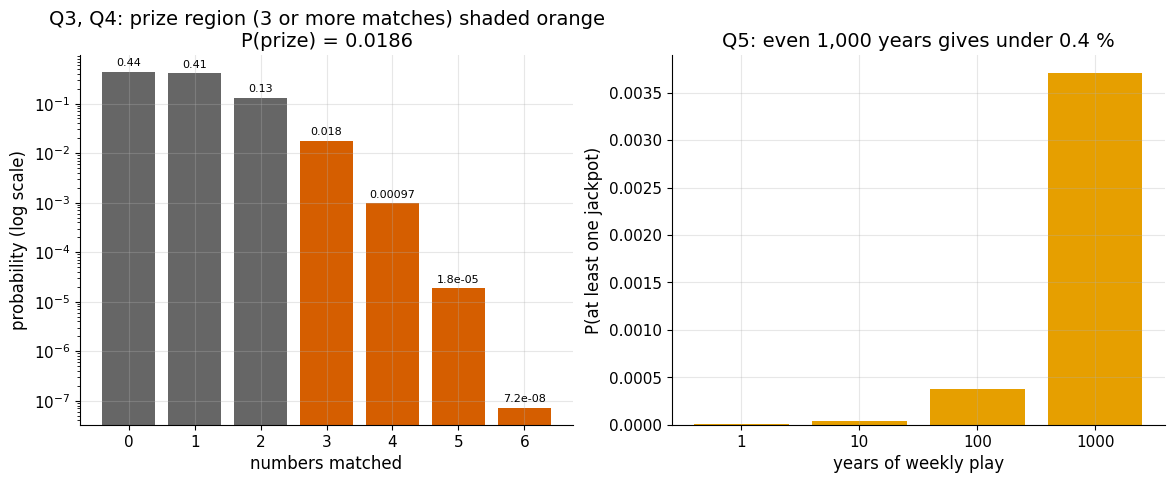

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ms = np.arange(7)
axes[0].bar(ms, [exact[m] / total for m in ms], color=[NEUTRAL, NEUTRAL, NEUTRAL, HIGHLIGHT, HIGHLIGHT, HIGHLIGHT, HIGHLIGHT])
axes[0].set_yscale("log"); axes[0].set_xlabel("numbers matched"); axes[0].set_ylabel("probability (log scale)")
axes[0].set_title("Q3, Q4: prize region (3 or more matches) shaded orange\nP(prize) = 0.0186")
for m in ms: axes[0].text(m, exact[m] / total * 1.3, f"{exact[m] / total:.2g}", ha="center", fontsize=8)
years = np.array([1, 10, 100, 1000]); axes[1].bar([str(y) for y in years], [1 - (1 - 1 / total) ** (52 * y) for y in years], color=SIM)
axes[1].set_xlabel("years of weekly play"); axes[1].set_ylabel("P(at least one jackpot)"); axes[1].set_title("Q5: even 1,000 years gives under 0.4 %")
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **The odds are tiny.** There are **13,983,816** different tickets, so the jackpot chance is 1 in 14 million ($7.15\times10^{-8}$). Even playing every week for 1,000 years (52,000 tickets) gives only a **0.37 %** chance of ever winning it.
- **Most tickets win nothing.** 43.6 % match no number and 41.3 % match one; only **1.86 %** (about 1 in 54) match at least 3 and win any prize, and exactly 3 matches happens 1.77 % of the time (1 in 57).
- **Counting and simulation agree.** The `scipy` hypergeometric distribution gives the same probabilities as the combinations, and 300,000 simulated draws reproduce them (for example exactly 3 matches: 0.01745 simulated against 0.01765 exact).
- **Decision.** A ticket is entertainment, not an investment: every extra number matched makes the prize about 15 to 20 times rarer, so choose lotteries by their prize tiers, not by lucky numbers (all tickets are equally likely).

---
### Example 2: the birthday problem in a class and a stadium

**Scenario.** How many people do we need before it is more likely than not that two of them share a birthday (ignore 29 February, all days equally likely)? What about a class of 30, and a group of 70?

### 11.6 By hand, in code and by simulation
**By hand.** $P(\text{all differ})=\prod_{j=0}^{n-1}\dfrac{365-j}{365}$. For $n=23$: $\dfrac{365}{365}\cdot\dfrac{364}{365}\cdots\dfrac{343}{365}=0.4927$, so $P(\text{shared})=0.5073$. For $n=30$: $0.7063$; $n=70$: $0.99916$.

n = 10: P(shared birthday) = 0.1169
n = 23: P(shared birthday) = 0.5073
n = 30: P(shared birthday) = 0.7063
n = 50: P(shared birthday) = 0.9704
n = 70: P(shared birthday) = 0.9992


smallest group with probability above 0.5: 23 | simulated P(shared) for 30 people: 0.7070 (exact 0.7063)
number of pairs of people: [45, 253, 435, 2415]


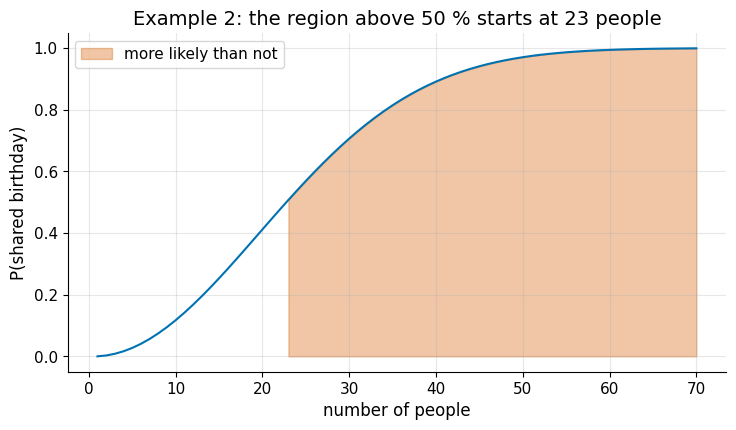

In [15]:
for n_people in (10, 23, 30, 50, 70):
    print(f"n = {n_people}: P(shared birthday) = {p_shared(n_people):.4f}")
first = next(n_ for n_ in range(1, 366) if p_shared(n_) > 0.5)
sim_rows = np.random.default_rng(8).integers(0, 365, size=(60_000, 30))
sim30 = np.mean([len(set(r_)) < 30 for r_ in sim_rows])
print(f"smallest group with probability above 0.5: {first} | simulated P(shared) for 30 people: {sim30:.4f} (exact {p_shared(30):.4f})")
assert first == 23 and abs(p_shared(23) - 0.5073) < 5e-4 and abs(p_shared(30) - 0.7063) < 5e-4 and abs(sim30 - p_shared(30)) < 0.01
pairs = [math.comb(n_, 2) for n_ in (10, 23, 30, 70)]
print("number of pairs of people:", pairs)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.fill_between(ns, 0, probs, where=probs >= 0.5, color=HIGHLIGHT, alpha=0.35, label="more likely than not"); ax.plot(ns, probs, color=MAIN)
ax.set_xlabel("number of people"); ax.set_ylabel("P(shared birthday)"); ax.set_title("Example 2: the region above 50 % starts at 23 people"); ax.legend()
plt.show()

### 11.6b Interpretation and decision (Example 2)
- With only **23 people** the chance that two share a birthday is already **50.7 %**; at 30 it is 70.6 %, at 50 it is 97.0 % and at 70 it is 99.92 %.
- The reason is that 23 people form **253 pairs**, and each pair is a chance for a match; the intuition "there are 365 days, so I need hundreds of people" forgets that all pairs count. (For somebody to match *your* birthday you do need about 253 people.)
- The simulation (60,000 groups of 30) gives 70.7 % against the exact 70.6 %.
- **Decision.** Whenever many items are compared pairwise (random IDs, hashes, usernames, test-set duplicates), expect collisions much earlier than the size of the space suggests: collisions become likely at about $\sqrt{\text{space size}}$ items.

---
### Example 3: poker hands (counting with several groups)

**Scenario.** A 5-card poker hand is dealt from a 52-card deck. How many different hands are there? What is the probability of a **full house** (three cards of one rank and two of another) and of a **flush** (five cards of the same suit, not a straight flush)?

### 11.7 By hand, in code and by simulation
**By hand.** Total hands $\binom{52}5=2{,}598{,}960$. **Full house:** choose the rank of the triple (13), choose its 3 suits ($\binom43=4$), choose a different rank for the pair (12), choose its 2 suits ($\binom42=6$): $13\times4\times12\times6=3{,}744$, so $P=0.00144$ (1 in 694). **Flush:** choose the suit (4) and any 5 of its 13 cards ($\binom{13}5=1287$), then remove the 10 straight flushes per suit ($40$ in all, including the royal flushes): $4\times1287-40=5{,}108$, so $P=0.00197$ (1 in 509).

hands 2,598,960 | full houses 3,744 (P = 0.00144, 1 in 694) | flushes 5,108 (P = 0.00197, 1 in 509)


simulated: full house 0.00133 (exact 0.00144), flush 0.00200 (exact 0.00197)


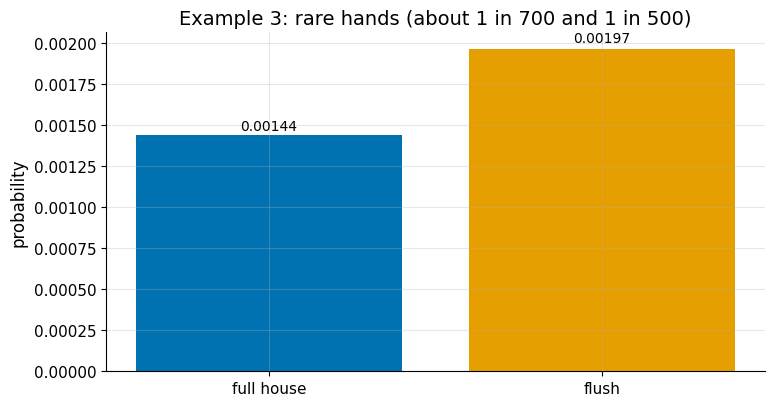

In [16]:
hands = math.comb(52, 5)
full_house = 13 * math.comb(4, 3) * 12 * math.comb(4, 2)
flush = 4 * math.comb(13, 5) - 40
print(f"hands {hands:,} | full houses {full_house:,} (P = {full_house / hands:.5f}, 1 in {hands / full_house:.0f}) | flushes {flush:,} (P = {flush / hands:.5f}, 1 in {hands / flush:.0f})")
assert hands == 2_598_960 and full_house == 3_744 and flush == 5_108
# simulate deals
deck_rank = np.repeat(np.arange(13), 4); deck_suit = np.tile(np.arange(4), 13)
deal_rng = np.random.default_rng(9)
n_deals = 600_000
idx = np.vstack([np.argsort(deal_rng.random((200_000, 52)), axis=1)[:, :5] for _ in range(3)])
ranks, suits = deck_rank[idx], deck_suit[idx]
rank_counts = np.sort(np.apply_along_axis(lambda r: np.bincount(r, minlength=13), 1, ranks), axis=1)[:, ::-1]
is_full = (rank_counts[:, 0] == 3) & (rank_counts[:, 1] == 2)
same_suit = (suits == suits[:, [0]]).all(axis=1)
sr = np.sort(ranks, axis=1); is_straight = ((sr[:, 4] - sr[:, 0] == 4) & (np.diff(sr, axis=1) == 1).all(axis=1)) | (sr == np.array([0, 1, 2, 3, 12])).all(axis=1)
is_flush = same_suit & ~is_straight
print(f"simulated: full house {is_full.mean():.5f} (exact {full_house / hands:.5f}), flush {is_flush.mean():.5f} (exact {flush / hands:.5f})")
assert abs(is_full.mean() - full_house / hands) < 0.0004 and abs(is_flush.mean() - flush / hands) < 0.0005
fig, ax = plt.subplots(figsize=(8.5, 4.4))
labels = ["full house", "flush"]; vals = [full_house / hands, flush / hands]
ax.bar(labels, vals, color=[MAIN, SIM]); ax.set_ylabel("probability"); ax.set_title("Example 3: rare hands (about 1 in 700 and 1 in 500)")
for i_, v_ in enumerate(vals): ax.text(i_, v_ * 1.02, f"{v_:.5f}", ha="center")
plt.show()

### 11.7b Interpretation and decision (Example 3)
- Of the **2,598,960** possible hands, 3,744 are full houses (1 in 694) and 5,108 are flushes (1 in 509): a flush is *more common* than a full house, which is why the full house ranks higher in poker.
- The simulation of 600,000 deals gives 0.00133 for a full house (exact 0.00144) and 0.00200 for a flush (exact 0.00197); the full-house gap is about two standard errors and shrinks with more deals (a separate run of 2 million deals gave 0.00147).
- **Decision.** In a card game, rank hands by how rare they are: counting the ways with the multiplication rule (rank, then suits, then the second rank) is far more reliable than intuition.

## 12. Where it is used

### Statistics
- **Combinatorics underlies the Binomial and Hypergeometric distributions** (Module 01) and all exact tests (Fisher's exact test counts tables); **permutation tests** (05_04) count rearrangements of the data.
- **Sampling designs** (05_08) count the possible samples: a simple random sample of $n$ from $N$ is one of $\binom Nn$ equally likely subsets.

### Data science
- **Search-space sizes:** how many feature subsets ($2^p$), hyperparameter grids (multiplication rule), A/B variant combinations.
- **Security and uniqueness:** password and ID spaces ($n^k$), collision probabilities (birthday problem) for **hash functions and random IDs**.

### ML and AI
- **Birthday bound in practice:** the chance that two random IDs, hashes or training samples collide grows like $n^2/2N$ (duplicate detection, deduplication of datasets).
- **Counting models and samples:** number of possible mini-batches $\binom Nb$, number of orderings in a shuffle ($N!$), and the size of the hypothesis class in generalisation bounds (05_05).

## 13. Common pitfalls and misconceptions

- **Order or no order?** Counting a lottery ticket with permutations overstates the number of tickets by $6!=720$. Ask: "if I swap two chosen items, is it a different outcome?"
- **Forgetting to divide for repeats:** arrangements of BANANA are $6!/(3!\,2!)=60$, not $720$.
- **Not all outcomes are equally likely:** the *sum* of two dice is not uniform, but the 36 *pairs* are. Count equally likely outcomes only.
- **Wrongly multiplying for "or":** multiply for "and then" (steps), add for "or" (separate cases, no overlap).
- **Birthday intuition:** the question is about **any pair** among $\binom n2$ pairs, not about someone matching *your* birthday (that needs about 253 people for 50 %).
- **Large factorials overflow:** use `math.comb`, or logarithms (`math.lgamma`) rather than dividing huge numbers by hand.
- **The lottery has no memory:** past draws do not change future probabilities (the gambler's fallacy, 05_01).

## 14. Exercises

1. A restaurant has 5 starters, 8 mains and 4 desserts. How many different 3-course meals are there? How many if you may also skip the dessert?
2. How many different 8-character passwords can be made from 26 lowercase letters and 10 digits (repetition allowed)? How many if no character may repeat? If a computer tries $10^9$ passwords per second, how long does the first set take to exhaust?
3. A committee of 4 is chosen from 12 people, 7 women and 5 men. How many committees are there? What is the probability that the committee has exactly 2 women?
4. How many distinct arrangements are there of the letters of MISSISSIPPI?
5. A fair coin is tossed 10 times. How many sequences have exactly 4 heads? What is the probability of exactly 4 heads?
6. (Harder) How many people are needed for the probability that two share a birthday to exceed 99 %? And how many for the probability that someone has *your* birthday to exceed 50 %?

Solutions are at the end.

## 15. Summary table

| Counting problem | Formula | Python |
|---|---|---|
| Steps with $m_1,\dots,m_k$ choices | $m_1\cdots m_k$ | `np.prod` |
| Sequences with repetition | $n^k$ | `n ** k` |
| Ordered picks, no repetition | $\dfrac{n!}{(n-k)!}$ | `math.perm(n, k)` |
| Arrange $n$ items | $n!$ | `math.factorial(n)` |
| Groups of $k$ from $n$ | $\binom nk$ | `math.comb(n, k)` |
| Arrangements with repeats | $\dfrac{n!}{n_1!n_2!\cdots}$ | `math.factorial` |
| Probability (equally likely) | favourable / total | `count / total` |
| Birthday (no match) | $\prod(1-j/365)$ | loop or `np.prod` |

## Solutions

In [17]:
print("1: 5*8*4 =", 5 * 8 * 4, "| with the dessert optional: 5*8*(4+1) =", 5 * 8 * 5)
sets_a, sets_b = 36**8, math.perm(36, 8)
print(f"2: with repeats {sets_a:,} | without {sets_b:,} | time at 1e9/s: {sets_a / 1e9 / 3600:.2f} hours and {sets_b / 1e9 / 3600:.2f} hours")
total_c = math.comb(12, 4); two_w = math.comb(7, 2) * math.comb(5, 2)
print(f"3: {total_c} committees; exactly 2 women: {two_w} -> P = {two_w / total_c:.4f}")
print("4:", math.factorial(11) // (math.factorial(4) * math.factorial(4) * math.factorial(2)), "arrangements of MISSISSIPPI (1 M, 4 I, 4 S, 2 P)")
print(f"5: {math.comb(10, 4)} sequences with 4 heads; P = {math.comb(10, 4) / 2**10:.4f}")
n99 = next(n_ for n_ in range(1, 366) if p_shared(n_) > 0.99)
n_me = next(n_ for n_ in range(1, 5000) if 1 - (364 / 365) ** n_ > 0.5)
print(f"6: {n99} people for a 99 % chance that some two share | {n_me} people for a 50 % chance that someone shares YOUR birthday")

1: 5*8*4 = 160 | with the dessert optional: 5*8*(4+1) = 200
2: with repeats 2,821,109,907,456 | without 1,220,096,908,800 | time at 1e9/s: 0.78 hours and 0.34 hours
3: 495 committees; exactly 2 women: 210 -> P = 0.4242
4: 34650 arrangements of MISSISSIPPI (1 M, 4 I, 4 S, 2 P)
5: 210 sequences with 4 heads; P = 0.2051
6: 57 people for a 99 % chance that some two share | 253 people for a 50 % chance that someone shares YOUR birthday


**1.** $5\times8\times4=\mathbf{160}$ meals; with an optional dessert there are $4+1=5$ dessert options: $5\times8\times5=\mathbf{200}$.

**2.** With repetition $36^8=\mathbf{2{,}821{,}109{,}907{,}456}$ (2.8 trillion). Without repetition $P(36,8)=\mathbf{1{,}220{,}096{,}908{,}800}$. At $10^9$ guesses per second the first set is exhausted in 0.78 hours (47 minutes) and the second in 0.34 hours (20 minutes): a short password is weak even with digits.

**3.** $\binom{12}4=\mathbf{495}$ committees; exactly 2 women: $\binom72\binom52=21\times10=210$, so $P=210/495=\mathbf{0.424}$.

**4.** MISSISSIPPI has 11 letters: 1 M, 4 I, 4 S, 2 P. $\dfrac{11!}{1!\,4!\,4!\,2!}=\mathbf{34{,}650}$.

**5.** $\binom{10}4=\mathbf{210}$ sequences, out of $2^{10}=1024$: $P=210/1024=\mathbf{0.205}$.

**6.** 57 people give a shared birthday with probability above 99 %. For *someone to share your birthday* with probability above 50 % you need $1-(364/365)^n>0.5$, i.e. $n=\mathbf{253}$ people.